# 比較器とシュミットトリガ

2 つの電圧を比べて、入力が**しきい値**より高いか低いかを、HIGH(5 V)か LOW(0 V)で出す回路です。アナログの信号を、マイコンが読める 0 / 1 に変える入り口になります。温度が設定値を超えたらヒーターを切る、光が暗くなったら街灯をつける、といった判定に使います。

この回では、正弦波を方形波にする、ゆっくり変わる入力で出力が何度も切り替わる(チャタリング)、それをヒステリシスで止める(シュミットトリガ)、の 3 つを見ます。

## 回路

![シュミットトリガ](01_comparator/circuit.svg)

オペアンプを帰還なしで使うと、わずかな入力の差が電源いっぱいまで増幅されるので、出力は HIGH か LOW のどちらかになります。これが**比較器**です(図から $R_2$ を外し、$R_1$ を線にした形。− 入力の電圧がしきい値)。実際には、比較器専用の IC(LM393 など)を使うのが普通です。

図は、出力を $R_2$ で + 入力に戻した(**正帰還**)**シュミットトリガ**です。出力が切り替わると + 入力の電圧も動くので、切り替わる入力の電圧が、上がるときと下がるときで違ってきます。

Mimic の比較器の出力は**デジタル**です。AOUT はマイコンのピンのように、0 V か 5 V(VCC)をそのまま出します。

## 原理

**比較器**:入力がしきい値より高ければ HIGH、低ければ LOW。入出力特性は、しきい値のところで切り替わる階段になります(下の図の左)。

問題は、しきい値の近くで入力に雑音が乗っているときです。入力がしきい値をゆっくり横切ると、雑音で何度も上下に横切るので、出力が HIGH と LOW のあいだで何度もばたばた切り替わります。これを**チャタリング**といいます。

**シュミットトリガ**:しきい値を 2 つにします。

| 今の出力 | 次に切り替わるのは |
|---|---|
| LOW | 入力が**上のしきい値**(upper)を超えたとき → HIGH |
| HIGH | 入力が**下のしきい値**(lower)を下回ったとき → LOW |

2 つのしきい値のあいだでは、出力は前の状態を保ちます。この幅を**ヒステリシス**といいます。雑音の大きさよりヒステリシスを広くすれば、チャタリングは起きません。入出力特性は、行きと帰りで違う道を通る四角いループになります(下の図の右。矢印が進む向き)。

![比較器とシュミットトリガの入出力特性(模式図)](01_comparator/response.svg)

図の回路(− 入力が Vref = 2.5 V、出力が 0 V と 5 V)では、+ 入力の電圧が Vref を横切るところで切り替わるので、

$$V_\mathrm{upper} = V_\mathrm{ref}\left(1 + \frac{R_1}{R_2}\right), \qquad V_\mathrm{lower} = V_\mathrm{upper} - 5\,\mathrm{V}\times\frac{R_1}{R_2}$$

です(導出は省きます)。ヒステリシスの幅は $5\,\mathrm{V}\times R_1/R_2$ です。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.comparator(th)` | `mimic.setComparatorSchmitt(th, th)` | 比較器。しきい値 th [V](上と下を同じにしたシュミットトリガ) |
| `lab.mimic.comparator_schmitt(upper, lower)` | `mimic.setComparatorSchmitt(upper, lower)` | シュミットトリガ。上と下のしきい値 [V] |

例:upper = 3.0 V、lower = 2.0 V は、幅 1 V なので $R_1/R_2$ = 0.2($R_1$ = 10 kΩ、$R_2$ = 50 kΩ)の、図の回路(− 入力は Vref の 2.5 V)にあたります。Mimic では 2 つのしきい値を直接決めます。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

波形(左)と、入出力特性(右:CH1 を横軸、CH2 を縦軸にした点)を並べて描く関数です。この章ではこれを使います。

In [2]:
def scope_xy(t, ch1, ch2, label="output", xlim=None):
    # Left: the oscilloscope; right: the input-output characteristic (CH1 across, CH2 up)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    if xlim:
        ax1.set_xlim(*xlim)
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".-", lw=0.5, ms=2, color="C2")   # thin lines show the transitions
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:正弦波を方形波にする

50 Hz、振幅 1 V の正弦波を、しきい値 2.5 V(Vref)の比較器に入れます。入力が 2.5 V より高い半周期は HIGH、低い半周期は LOW の方形波になるはずです。HIGH の時間の割合(**デューティ比**)も計算します。

duty: 50.2 % (theory 50 %)


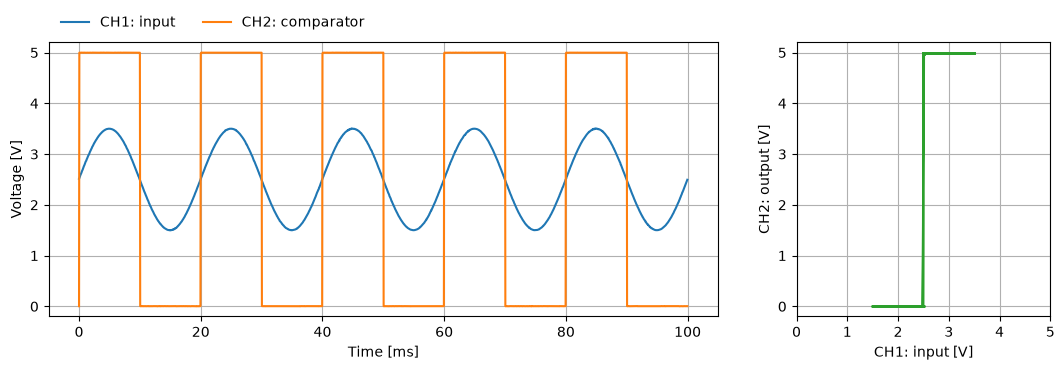

In [3]:
lab.fg.sine(50, 1.0)
lab.mimic.comparator(2.5)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"duty: {np.mean(ch2 > 2.5) * 100:.1f} % (theory 50 %)")
scope_xy(t, ch1, ch2, "comparator")

入出力特性(右)は、2.5 V のところで LOW から HIGH に切り替わる階段です。正弦波の形(振幅)の情報はなくなり、「しきい値より上か下か」だけが残ります。

## 実験 2:ゆっくり変わる入力(チャタリング)

2 Hz、振幅 0.5 V、中心 2.4 V の三角波を入れます。入力は 1 秒に 4 V というゆっくりした速さで上がっていき、取り込みを始めてから 25 ms のところで、しきい値の 2.5 V を横切ります。

入力には、Mimic の入力の雑音(数 mV)が乗っています。しきい値の近くに入力がとどまるあいだ、雑音で何度も横切るので、出力が何度も切り替わるはずです。切り替わった回数を数えます。

comparator: switched 3 times


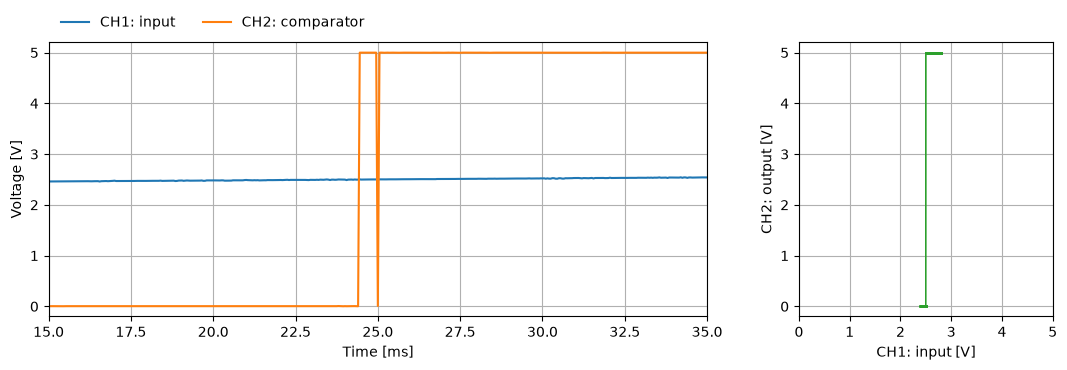

In [4]:
lab.fg.triangle(2, 0.5, 2.4)
lab.mimic.comparator(2.5)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
high = ch2 > 2.5
print(f"comparator: switched {np.count_nonzero(high[1:] != high[:-1])} times")
scope_xy(t, ch1, ch2, "comparator", xlim=(15, 35))

波形は、しきい値を横切るあたり(15〜35 ms)を拡大しています。理屈では 1 回だけ切り替わるはずなのに、何回も HIGH と LOW を行き来しているのが見えます(回数は実行するたびに変わります)。

次に、しきい値を upper = 2.6 V、lower = 2.4 V のシュミットトリガにして、同じ入力を入れます。

Schmitt trigger: switched 1 times


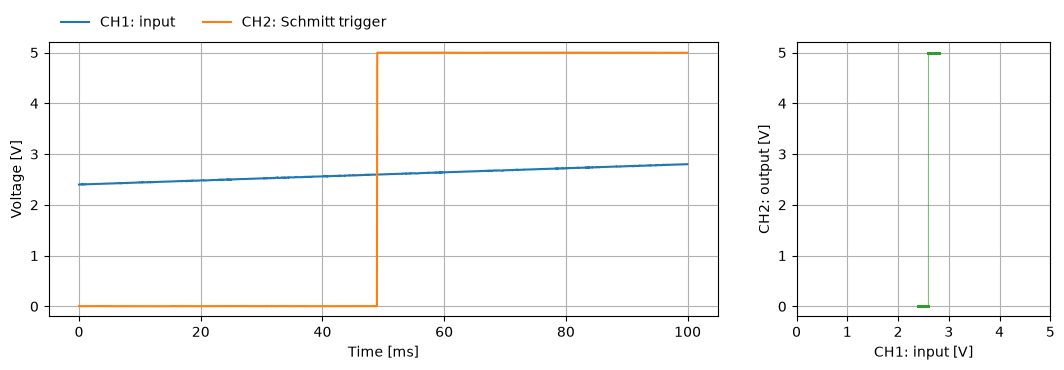

In [5]:
lab.mimic.comparator_schmitt(2.6, 2.4)
t, ch1, ch2 = lab.scope.capture(2000)
high = ch2 > 2.5
print(f"Schmitt trigger: switched {np.count_nonzero(high[1:] != high[:-1])} times")
scope_xy(t, ch1, ch2, "Schmitt trigger")

出力は 1 回だけ、入力が 2.6 V を超えたところできれいに切り替わります。一度 HIGH になると、入力が 2.4 V を下回るまで LOW に戻らないので、雑音(数 mV)では戻りません。

## 実験 3:ヒステリシスを見る

50 Hz、振幅 1 V の正弦波を、upper = 3.0 V、lower = 2.0 V のシュミットトリガに入れます。出力が LOW から HIGH に変わるのは入力が 3.0 V を超えたとき、HIGH から LOW に変わるのは 2.0 V を下回ったときのはずです。切り替わったときの入力の電圧を調べます。

LOW -> HIGH at 3.01 V (upper 3.0 V), HIGH -> LOW at 1.99 V (lower 2.0 V)


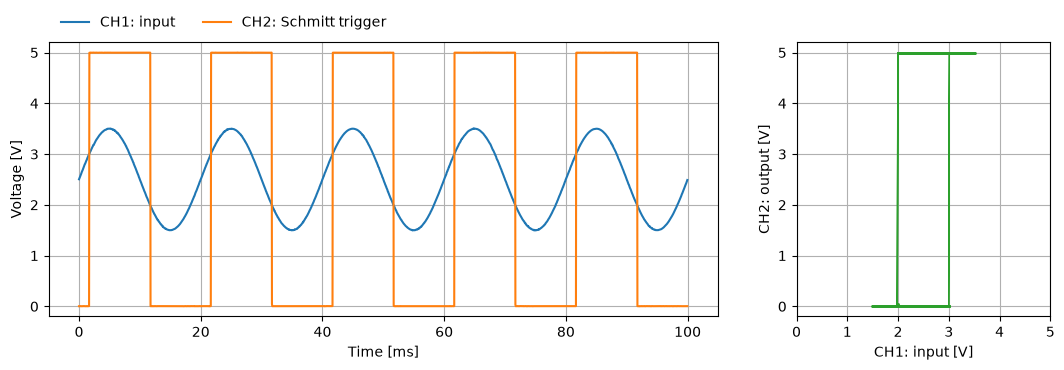

In [6]:
lab.fg.sine(50, 1.0)
lab.mimic.comparator_schmitt(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
high = ch2 > 2.5
up = np.flatnonzero(~high[:-1] & high[1:]) + 1      # LOW -> HIGH
down = np.flatnonzero(high[:-1] & ~high[1:]) + 1    # HIGH -> LOW
print(f"LOW -> HIGH at {ch1[up].mean():.2f} V (upper 3.0 V), HIGH -> LOW at {ch1[down].mean():.2f} V (lower 2.0 V)")
scope_xy(t, ch1, ch2, "Schmitt trigger")

入出力特性(右)は、行きと帰りで違う道を通るループになります(上の模式図の右と同じ形)。切り替わりの電圧がしきい値より少しだけ外側になるのは、Mimic の遅れ(約 30 µs)のあいだに入力が少し進むためです。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. しきい値を変える

正弦波を比較器に入れたまま、しきい値を変えて、方形波のデューティ比を見ます。
<details><summary>ヒント</summary>

`THRESHOLD` を 2.5 → 3.0 → 3.4 → 3.6 と変えてみましょう。しきい値を上げるほど HIGH の時間が短くなり、デューティ比は 50 %、33 %、14 % と小さくなります(振幅 1 V の正弦波が中心から $x$ V 上を超えている時間の割合は $\arccos(x)/\pi$)。3.6 V は正弦波の山(3.5 V)より高いので、出力はずっと LOW です。

</details>

duty: 50.0 % (theory 50.0 %)


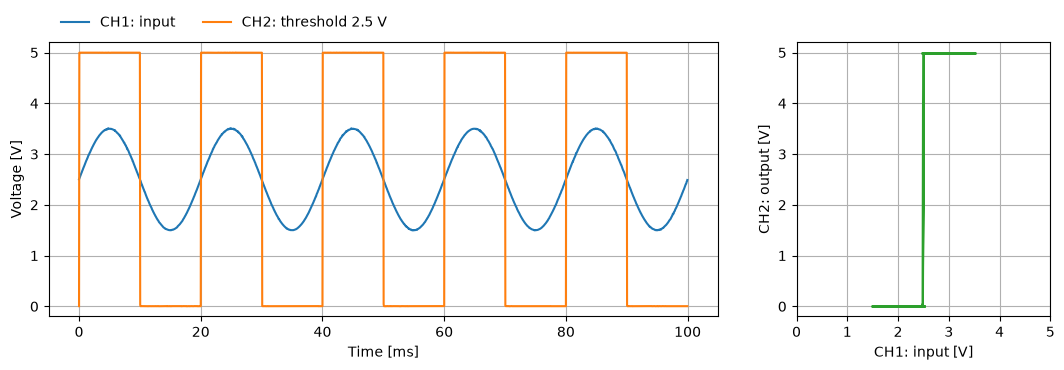

In [7]:
THRESHOLD = 2.5   # [V]

lab.fg.sine(50, 1.0)
lab.mimic.comparator(THRESHOLD)
t, ch1, ch2 = lab.scope.capture(2000)
x = min(max(THRESHOLD - 2.5, -1), 1)
print(f"duty: {np.mean(ch2 > 2.5) * 100:.1f} % (theory {np.degrees(np.arccos(x)) / 180 * 100:.1f} %)")
scope_xy(t, ch1, ch2, f"threshold {THRESHOLD} V")

### 2. チャタリングを止めるのに要るヒステリシス

実験 2 のゆっくりした三角波で、ヒステリシスの幅を変えて、切り替わる回数を数えます。
<details><summary>ヒント</summary>

`HYST`(ヒステリシスの幅)を 0 → 0.005 → 0.02 → 0.05 → 0.2 と変えてみましょう(しきい値は 2.5 V ± 幅の半分)。0 では何回も切り替わり、幅を広げていくと、ある幅からは 1 回になります。それが入力の雑音の大きさ(ピークからピーク)の目安です。何度か実行して、回数がばらつくようすも見てください。

</details>

hysteresis 0 mV: switched 3 times


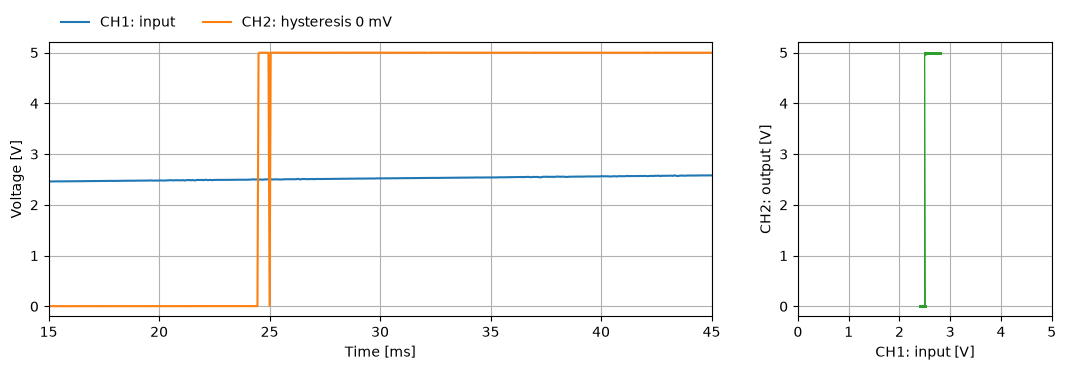

In [8]:
HYST = 0.0   # width of the hysteresis [V]

lab.fg.triangle(2, 0.5, 2.4)
lab.mimic.comparator_schmitt(2.5 + HYST / 2, 2.5 - HYST / 2)
t, ch1, ch2 = lab.scope.capture(2000)
high = ch2 > 2.5
print(f"hysteresis {HYST * 1e3:.0f} mV: switched {np.count_nonzero(high[1:] != high[:-1])} times")
scope_xy(t, ch1, ch2, f"hysteresis {HYST * 1e3:.0f} mV", xlim=(15, 45))

### 3. ヒステリシスより小さい入力

シュミットトリガ(3.0 V / 2.0 V)に入れる正弦波の振幅を小さくしていきます。出力はどうなるでしょうか。
<details><summary>ヒント</summary>

`AMP` を 1.0 → 0.6 → 0.4 と変えてみましょう。0.4 V では、入力(2.1〜2.9 V)が 2 つのしきい値のどちらにも届かないので、出力は**切り替わらず、前の状態のまま**です(HIGH のままか LOW のままかは、その前に何をしたかで決まります)。ヒステリシスは「小さな変化を無視する」働きでもあります。

</details>

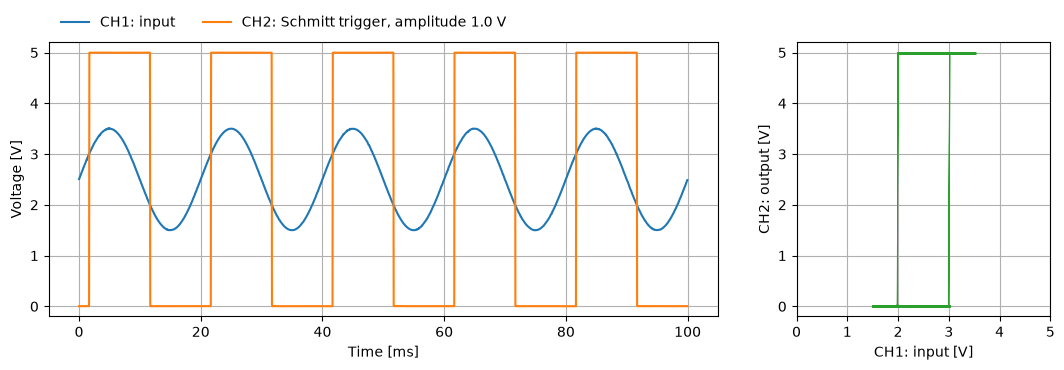

In [9]:
AMP = 1.0   # [V]

lab.fg.sine(50, AMP)
lab.mimic.comparator_schmitt(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
scope_xy(t, ch1, ch2, f"Schmitt trigger, amplitude {AMP} V")

## まとめ

- 比較器は、入力がしきい値より高いか低いかを HIGH / LOW で出す。Mimic の出力はデジタル(0 V / 5 V)。
- しきい値の近くをゆっくり横切ると、雑音で出力が何度も切り替わる(チャタリング)。
- シュミットトリガは、上と下の 2 つのしきい値(ヒステリシス)を持ち、雑音より広い幅でチャタリングを止める。回路では正帰還($R_2$)で作り、幅は $5\,\mathrm{V}\times R_1/R_2$。
- Mimic では `comparator(th)`、`comparator_schmitt(upper, lower)`。


最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()